In [9]:
from google.colab import drive
drive.mount('/content/drive')
import os, pandas as pd
DATA = "/content/drive/MyDrive/elliptic_pp"
print(os.listdir(DATA))

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
['Copy of Copy of txs_features.csv', 'Copy of Copy of txs_classes.csv', 'Copy of Copy of txs_edgelist.csv', 'illicit_per_step.png', 'static_f1_per_step.png', 'per_step_metrics.csv']


In [10]:
F = f"{DATA}/Copy of Copy of txs_features.csv"
C = f"{DATA}/Copy of Copy of txs_classes.csv"
E = f"{DATA}/Copy of Copy of txs_edgelist.csv"

feat = pd.read_csv(F)
cls  = pd.read_csv(C)

print("features shape:", feat.shape)
print("first columns:", list(feat.columns[:6]))
print("last columns:", list(feat.columns[-4:]))
print("classes shape:", cls.shape)
print(cls.head())
print(cls.iloc[:, 1].value_counts())

features shape: (203769, 184)
first columns: ['txId', 'Time step', 'Local_feature_1', 'Local_feature_2', 'Local_feature_3', 'Local_feature_4']
last columns: ['out_BTC_max', 'out_BTC_mean', 'out_BTC_median', 'out_BTC_total']
classes shape: (203769, 2)
    txId  class
0   3321      3
1  11108      3
2  51816      3
3  68869      2
4  89273      2
class
3    157205
2     42019
1      4545
Name: count, dtype: int64


In [11]:
df = feat.merge(cls, on="txId", how="inner")
df = df.rename(columns={"Time step": "time"})
df["label"] = df["class"].map({1: 1, 2: 0, 3: -1})   # 1=illicit, 0=licit, -1=unknown
FEATS = [c for c in df.columns if c not in ["txId", "time", "class", "label"]]
print(len(df), len(FEATS))
print(df["label"].value_counts())
print(df["time"].min(), df["time"].max())

203769 182
label
-1    157205
 0     42019
 1      4545
Name: count, dtype: int64
1 49


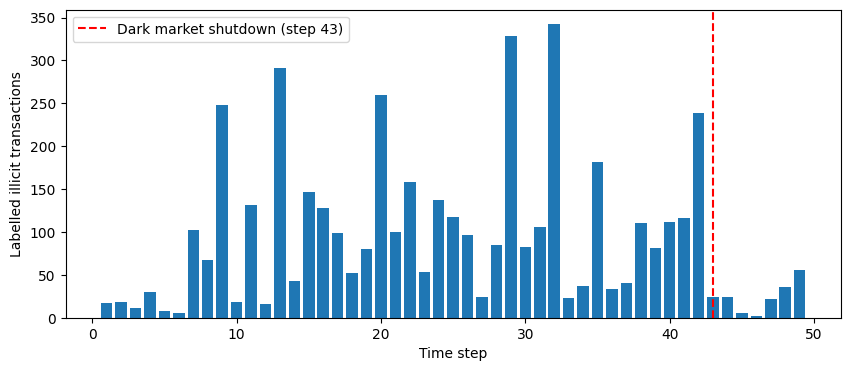

time
35    182
36     33
37     40
38    111
39     81
40    112
41    116
42    239
43     24
44     24
45      5
46      2
47     22
48     36
49     56


In [12]:
import matplotlib.pyplot as plt
c = df[df.label == 1].groupby("time").size().reindex(range(1, 50), fill_value=0)
plt.figure(figsize=(10, 4)); plt.bar(c.index, c.values)
plt.axvline(43, color="red", ls="--", label="Dark market shutdown (step 43)")
plt.xlabel("Time step"); plt.ylabel("Labelled illicit transactions"); plt.legend()
plt.savefig(f"{DATA}/illicit_per_step.png", dpi=200, bbox_inches="tight"); plt.show()
print(c.loc[35:].to_string())

In [13]:
TRAIN_STEPS = range(1, 35); TEST_STEPS = range(35, 50)
lab = df[df.label != -1]                       # unknowns are never used as labels
train = lab[lab.time.isin(TRAIN_STEPS)]
test  = lab[lab.time.isin(TEST_STEPS)]

def check_no_leakage(train, test):
    assert train.time.max() < test.time.min(), "future data in training!"
    assert set(train.txId).isdisjoint(set(test.txId)), "same transaction in both!"

check_no_leakage(train, test); print("leakage check passed", len(train), len(test))
try:
    check_no_leakage(test, train)              # swapped on purpose
except AssertionError as e:
    print("good, it fails when swapped:", e)

leakage check passed 29894 16670
good, it fails when swapped: future data in training!


In [14]:
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import precision_recall_fscore_support, average_precision_score
rf = RandomForestClassifier(n_estimators=100, random_state=42, n_jobs=-1)
rf.fit(train[FEATS], train["label"])
p = rf.predict_proba(test[FEATS])[:, 1]
yhat = (p > 0.5).astype(int)
pr, rc, f1, _ = precision_recall_fscore_support(test["label"], yhat, labels=[1], zero_division=0)
print(f"precision {pr[0]:.3f}  recall {rc[0]:.3f}  F1 {f1[0]:.3f}  PR-AUC {average_precision_score(test['label'], p):.3f}")

precision 0.971  recall 0.720  F1 0.827  PR-AUC 0.790


 time  n_illicit  precision  recall    F1
   35        182      0.978   0.967 0.972
   36         33      1.000   0.970 0.985
   37         40      0.962   0.625 0.758
   38        111      1.000   0.901 0.948
   39         81      0.987   0.926 0.955
   40        112      0.961   0.661 0.783
   41        116      1.000   0.914 0.955
   42        239      0.990   0.791 0.879
   43         24      0.000   0.000 0.000
   44         24      0.125   0.042 0.062
   45          5      0.000   0.000 0.000
   46          2      0.333   0.500 0.400
   47         22      0.000   0.000 0.000
   48         36      0.000   0.000 0.000
   49         56      0.500   0.018 0.034
steps 35-42 illicit: 914 P 0.986 R 0.850 F1 0.913
steps 43-49 illicit: 169 P 0.200 R 0.018 F1 0.033


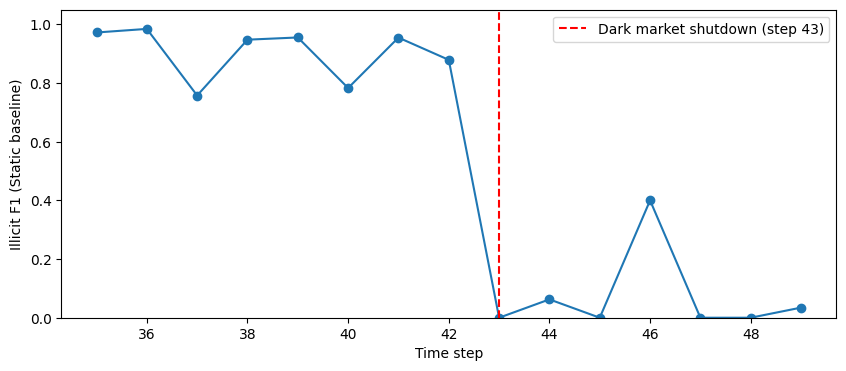

In [15]:
rows = []
for t in TEST_STEPS:
    m = (test.time == t).values
    y, yh = test["label"].values[m], yhat[m]
    n_ill = int(y.sum())
    if n_ill == 0: continue
    pr_, rc_, f1_, _ = precision_recall_fscore_support(y, yh, labels=[1], zero_division=0)
    rows.append((t, n_ill, pr_[0], rc_[0], f1_[0]))
per_step = pd.DataFrame(rows, columns=["time", "n_illicit", "precision", "recall", "F1"])
print(per_step.round(3).to_string(index=False))

for name, steps in [("steps 35-42", range(35, 43)), ("steps 43-49", range(43, 50))]:
    m = test.time.isin(steps).values
    pr_, rc_, f1_, _ = precision_recall_fscore_support(test["label"].values[m], yhat[m], labels=[1], zero_division=0)
    print(name, "illicit:", int(test["label"].values[m].sum()),
          f"P {pr_[0]:.3f} R {rc_[0]:.3f} F1 {f1_[0]:.3f}")

plt.figure(figsize=(10, 4)); plt.plot(per_step.time, per_step.F1, marker="o")
plt.axvline(43, color="red", ls="--", label="Dark market shutdown (step 43)")
plt.xlabel("Time step"); plt.ylabel("Illicit F1 (Static baseline)"); plt.ylim(0, 1.05); plt.legend()
plt.savefig(f"{DATA}/static_f1_per_step.png", dpi=200, bbox_inches="tight"); plt.show()
per_step.to_csv(f"{DATA}/per_step_metrics.csv", index=False)